# 06 - Results

Summary of the project from the files in `reports/`. Nothing is trained or recomputed here, so it runs in seconds and shows what the other notebooks saved. The README tables are generated by this notebook.

In [1]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from netad.evaluation import FIGURES_DIR, REPORTS_DIR, results_table

In [2]:
def markdown_table(df, formats):
    """df as a Markdown table; `formats` maps a column to a format string, e.g. "{:.1%}"."""
    header = "| " + " | ".join([df.index.name or ""] + list(df.columns)) + " |"
    lines = [header, "|" + "---|" * (len(df.columns) + 1)]
    for name, row in df.iterrows():
        cells = [formats.get(col, "{}").format(value) for col, value in row.items()]
        lines.append("| " + " | ".join([str(name)] + cells) + " |")
    return "\n".join(lines)

## Binary detection

Threshold at 1% FPR on validation for every model, results on test. Recall and FPR on all rows give the alert volume on the traffic as it comes; recall and `macro_detection` on distinct rows are what models are compared on (repeated flows don't count twice). The random forest is the model selected on validation.

In [3]:
models = ["LogisticRegression", "RandomForest", "HistGradientBoosting", "IsolationForest", "Autoencoder"]
test = results_table("binary", "test", ["recall", "fpr", "precision", "roc_auc"]).loc[models]
distinct = results_table("binary", "test_distinct", ["recall", "macro_detection"]).loc[models]

binary = pd.DataFrame({
    "trained on": ["attacks + normal"] * 3 + ["normal only"] * 2,
    "recall": test["recall"],
    "FPR": test["fpr"],
    "precision": test["precision"],
    "ROC-AUC": test["roc_auc"],
    "recall, distinct": distinct["recall"],
    "macro detection, distinct": distinct["macro_detection"],
}).rename_axis("model")
binary

,trained on,recall,FPR,precision,ROC-AUC,"recall, distinct","macro detection, distinct"
model,,,,,,,
LogisticRegression,attacks + normal,0.804222,0.025162,0.975099,0.967559,0.631446,0.693885
RandomForest,attacks + normal,0.890519,0.039730,0.964865,0.981635,0.798427,0.859265
HistGradientBoosting,attacks + normal,0.919505,0.048081,0.959068,0.984879,0.854731,0.903731
IsolationForest,normal only,0.611489,0.026378,0.965988,0.881065,0.294540,0.378221
Autoencoder,normal only,0.606040,0.031216,0.959655,0.908388,0.303924,0.373144


In [4]:
pct = "{:.1%}"
display(Markdown(markdown_table(binary, {
    "recall": pct, "FPR": pct, "precision": pct, "ROC-AUC": "{:.3f}",
    "recall, distinct": pct, "macro detection, distinct": "{:.2f}",
})))

| model | trained on | recall | FPR | precision | ROC-AUC | recall, distinct | macro detection, distinct |
|---|---|---|---|---|---|---|---|
| LogisticRegression | attacks + normal | 80.4% | 2.5% | 97.5% | 0.968 | 63.1% | 0.69 |
| RandomForest | attacks + normal | 89.1% | 4.0% | 96.5% | 0.982 | 79.8% | 0.86 |
| HistGradientBoosting | attacks + normal | 92.0% | 4.8% | 95.9% | 0.985 | 85.5% | 0.90 |
| IsolationForest | normal only | 61.1% | 2.6% | 96.6% | 0.881 | 29.5% | 0.38 |
| Autoencoder | normal only | 60.6% | 3.1% | 96.0% | 0.908 | 30.4% | 0.37 |

## Attack category (multi-class)

In [5]:
multi_models = ["LogisticRegression", "RandomForest", "HistGradientBoosting"]
mt = results_table("multiclass", "test", ["accuracy", "macro_f1"]).loc[multi_models]
md_ = results_table("multiclass", "test_distinct", ["macro_f1"]).loc[multi_models]
mv = results_table("multiclass", "val", ["macro_f1"]).loc[multi_models]
multiclass = pd.DataFrame({
    "macro-F1, validation": mv["macro_f1"],
    "accuracy": mt["accuracy"],
    "macro-F1": mt["macro_f1"],
    "macro-F1, distinct": md_["macro_f1"],
}).rename_axis("model")
display(multiclass.round(3))
display(Markdown(markdown_table(multiclass, {c: "{:.2f}" for c in multiclass.columns} | {"accuracy": pct})))

,"macro-F1, validation",accuracy,macro-F1,"macro-F1, distinct"
model,,,,
LogisticRegression,0.519,0.729,0.399,0.392
RandomForest,0.742,0.703,0.504,0.520
HistGradientBoosting,0.738,0.712,0.509,0.519


| model | macro-F1, validation | accuracy | macro-F1 | macro-F1, distinct |
|---|---|---|---|---|
| LogisticRegression | 0.52 | 72.9% | 0.40 | 0.39 |
| RandomForest | 0.74 | 70.3% | 0.50 | 0.52 |
| HistGradientBoosting | 0.74 | 71.2% | 0.51 | 0.52 |

## Detection per attack category (random forest, distinct test rows)

In [6]:
rf = json.loads((REPORTS_DIR / "results.json").read_text(encoding="utf-8"))
rf = next(r for r in rf if (r["model"], r["task"]) == ("RandomForest", "binary"))
per_category = pd.Series({c: v["flagged"] for c, v in rf["test_distinct"]["by_category"].items()}, name="flagged")
per_category.sort_values().round(3)

Normal            0.039
Fuzzers           0.303
Analysis          0.870
Shellcode         0.870
DoS               0.919
Exploits          0.928
Worms             0.932
Reconnaissance    0.954
Generic           0.976
Backdoor          0.980
Name: flagged, dtype: float64

## Leave one attack out, over three seeds

In [7]:
seeds = pd.read_csv(REPORTS_DIR / "leave_one_out_seeds.csv")
loo = seeds.groupby(["category", "model"])["detection"].agg(["min", "max"]).unstack("model")
loo = loo.swaplevel(axis=1).sort_index(axis=1)
loo.round(3)

model          Autoencoder        IsolationForest        RandomForest       
                       max    min             max    min          max    min
category                                                                    
Analysis             0.776  0.464           0.823  0.789        0.870  0.868
Backdoor             0.824  0.653           0.847  0.841        0.968  0.960
DoS                  0.376  0.300           0.391  0.381        0.895  0.889
Exploits             0.314  0.205           0.179  0.159        0.776  0.758
Fuzzers              0.122  0.081           0.115  0.110        0.339  0.294
Generic              0.871  0.801           0.844  0.800        0.351  0.287
Reconnaissance       0.091  0.044           0.096  0.089        0.491  0.459
Shellcode            0.005  0.003           0.000  0.000        0.810  0.783
Worms                0.182  0.159           0.159  0.159        0.955  0.932

## Figures

**binary_roc_pr**

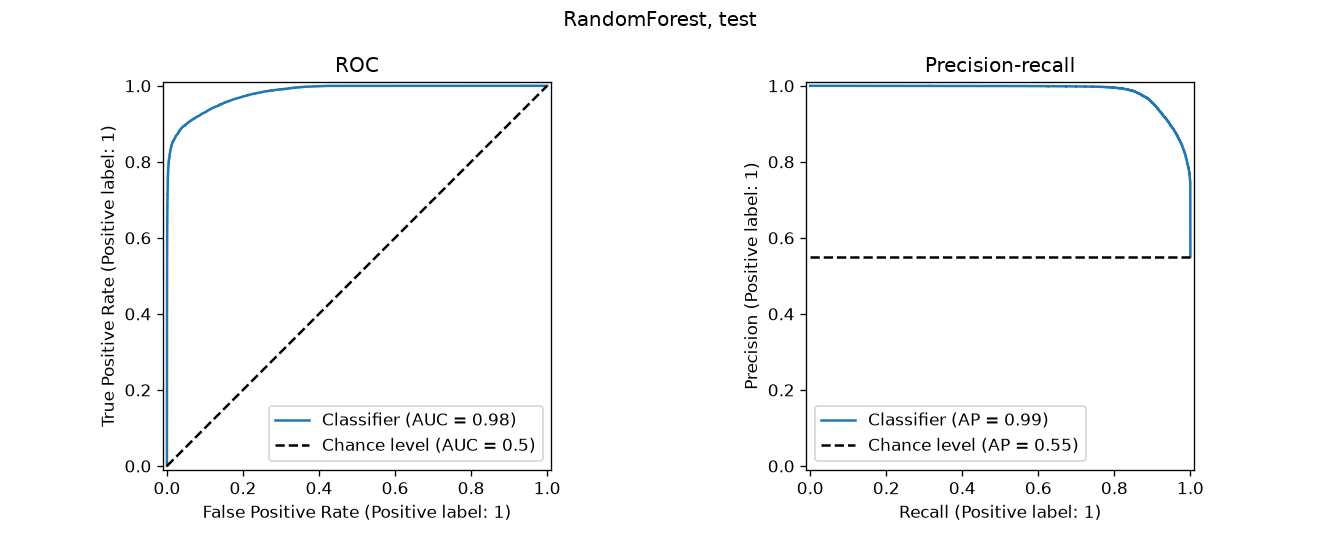

**binary_detection_by_category**

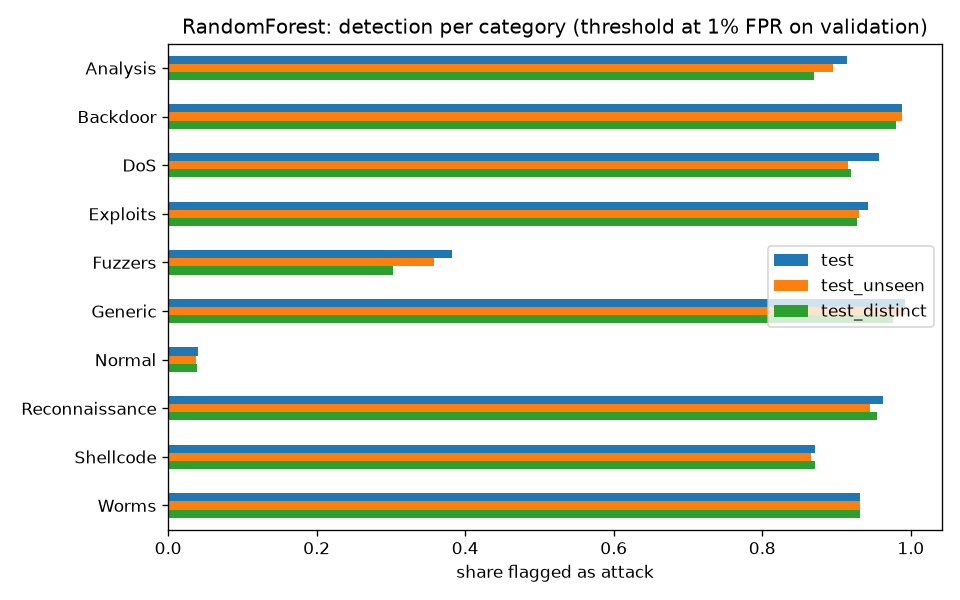

**binary_normal_scores**

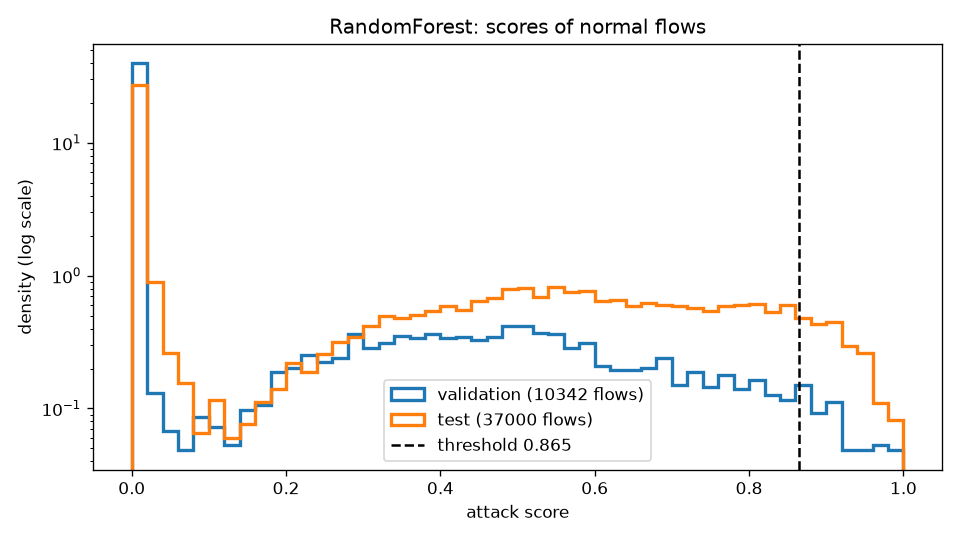

**anomaly_detection_by_category**

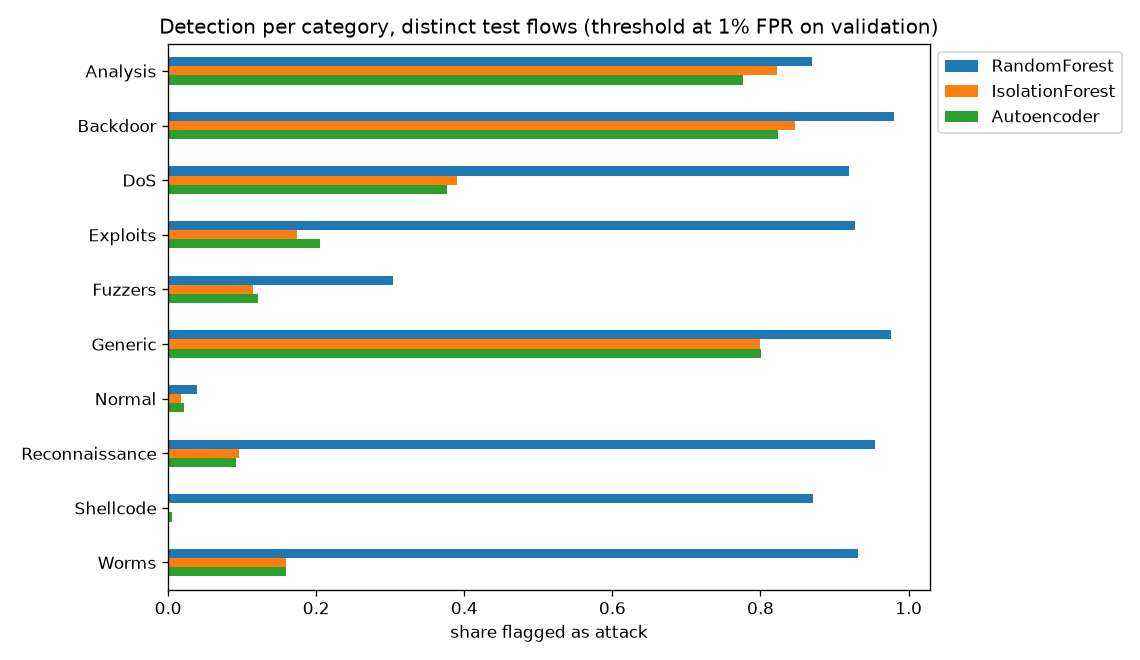

**leave_one_out**

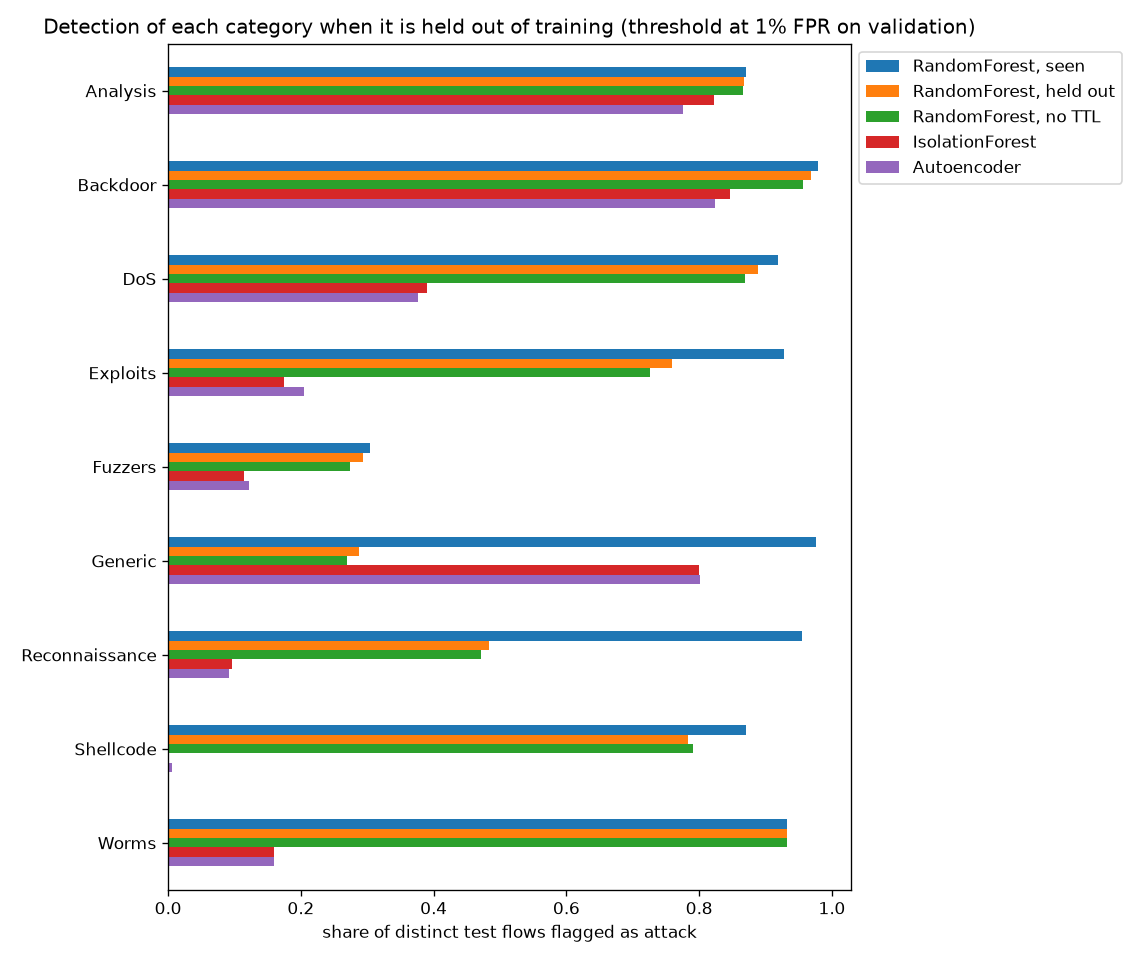

**leave_one_out_curves**

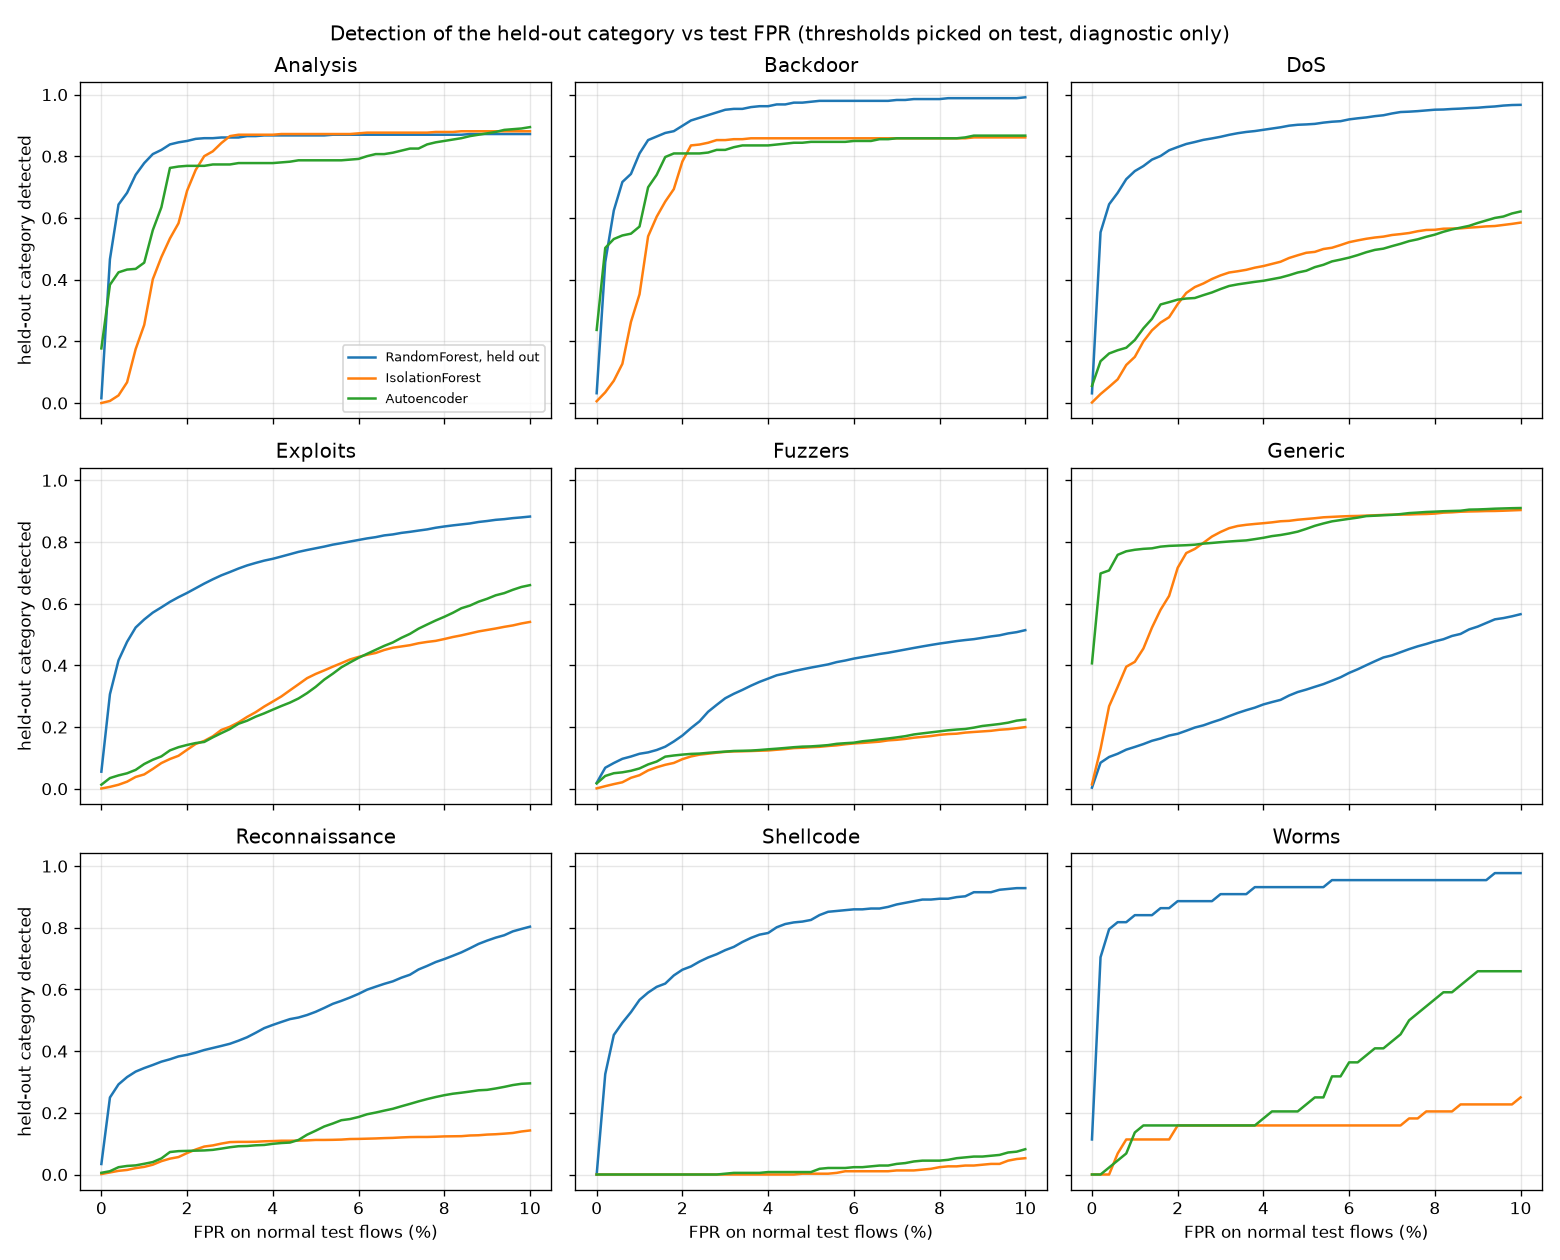

**multiclass_confusion**

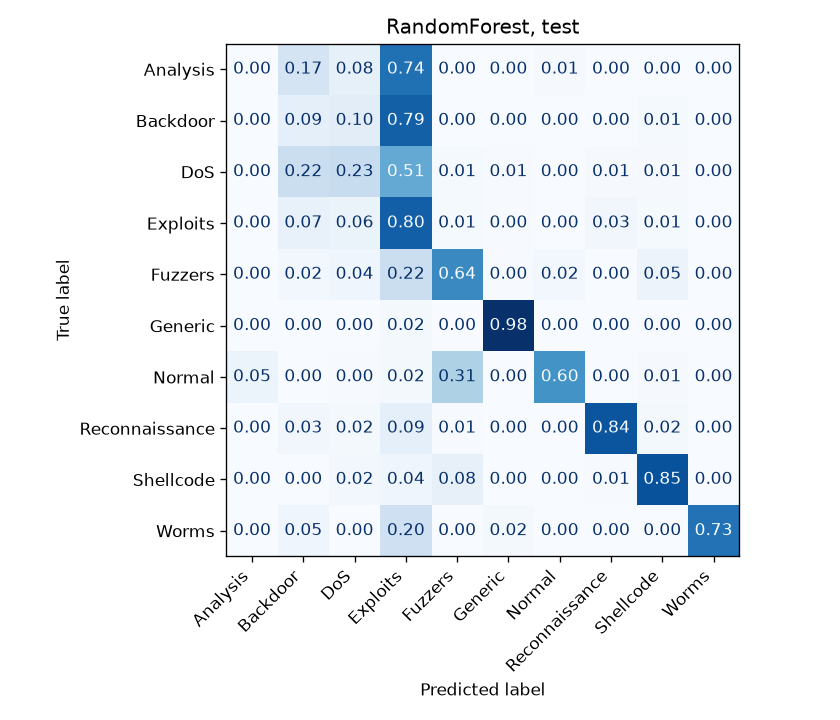

In [8]:
for name in ["binary_roc_pr", "binary_detection_by_category", "binary_normal_scores", "anomaly_detection_by_category",
             "leave_one_out", "leave_one_out_curves", "multiclass_confusion"]:
    display(Markdown(f"**{name}**"))
    display(Image(filename=FIGURES_DIR / f"{name}.png"))